# Simple Non-Linear Model Using Keras Functional API 

In [1]:
from keras.models import Model
from keras.layers import *

In [2]:
x = Input(shape= (3,))

In [3]:
hidden1 = Dense(128 , activation = 'relu')(x)
hidden2 = Dense(64, activation='relu')(hidden1)

# Branching
output1 = Dense(1 , activation='linear')(hidden2)
output2 = Dense(1 , activation='sigmoid')(hidden2)

In [4]:
model = Model(inputs = x, outputs= [output1 , output2])

In [5]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │        512 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         65 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         65 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,898 (34.76 KB)

 Trainable params: 8,898 (34.76 KB)

 Non-trainable params: 0 (0.00 B)

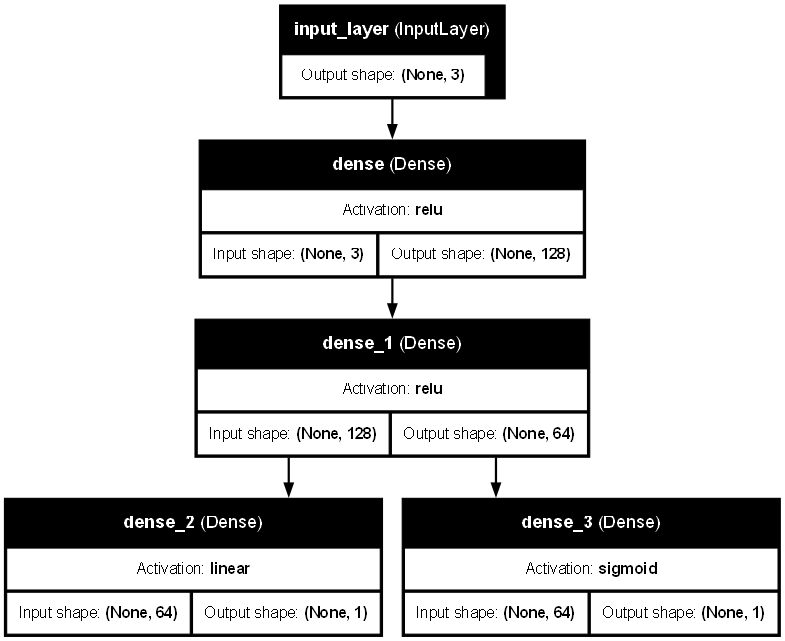

In [12]:
from keras.utils import plot_model
plot_model(model,show_shapes=True, show_layer_names=True, show_layer_activations=True, rankdir='TB', expand_nested=True, dpi = 80)

# Better Architecture - Have Multiple Inputs

In [23]:
import os
curr_dir = os.getcwd()
curr_dir

'd:\\Notes of CampusX\\dl'

In [17]:
# Inputs
input1 = Input(shape= (32,))
input2 = Input(shape= (128,))

# Branch 1
I1D1 = Dense(8, activation='relu')(input1)
I1D2 = Dense(4, activation='relu')(I1D1)

# Branch 2
I2D1 = Dense(64, activation='relu')(input2)
I2D2 = Dense(32, activation='relu')(I2D1)
I2D3 = Dense(4, activation='relu')(I2D2)

In [18]:
combine_branch = concatenate([I1D2, I2D3]) # Concatenate outputs of each branch

In [19]:
z = Dense(2, activation='relu')(combine_branch)
z1 = Dense(1, activation='sigmoid')(z)

In [20]:
model = Model(inputs=[input1, input2], outputs=z1)

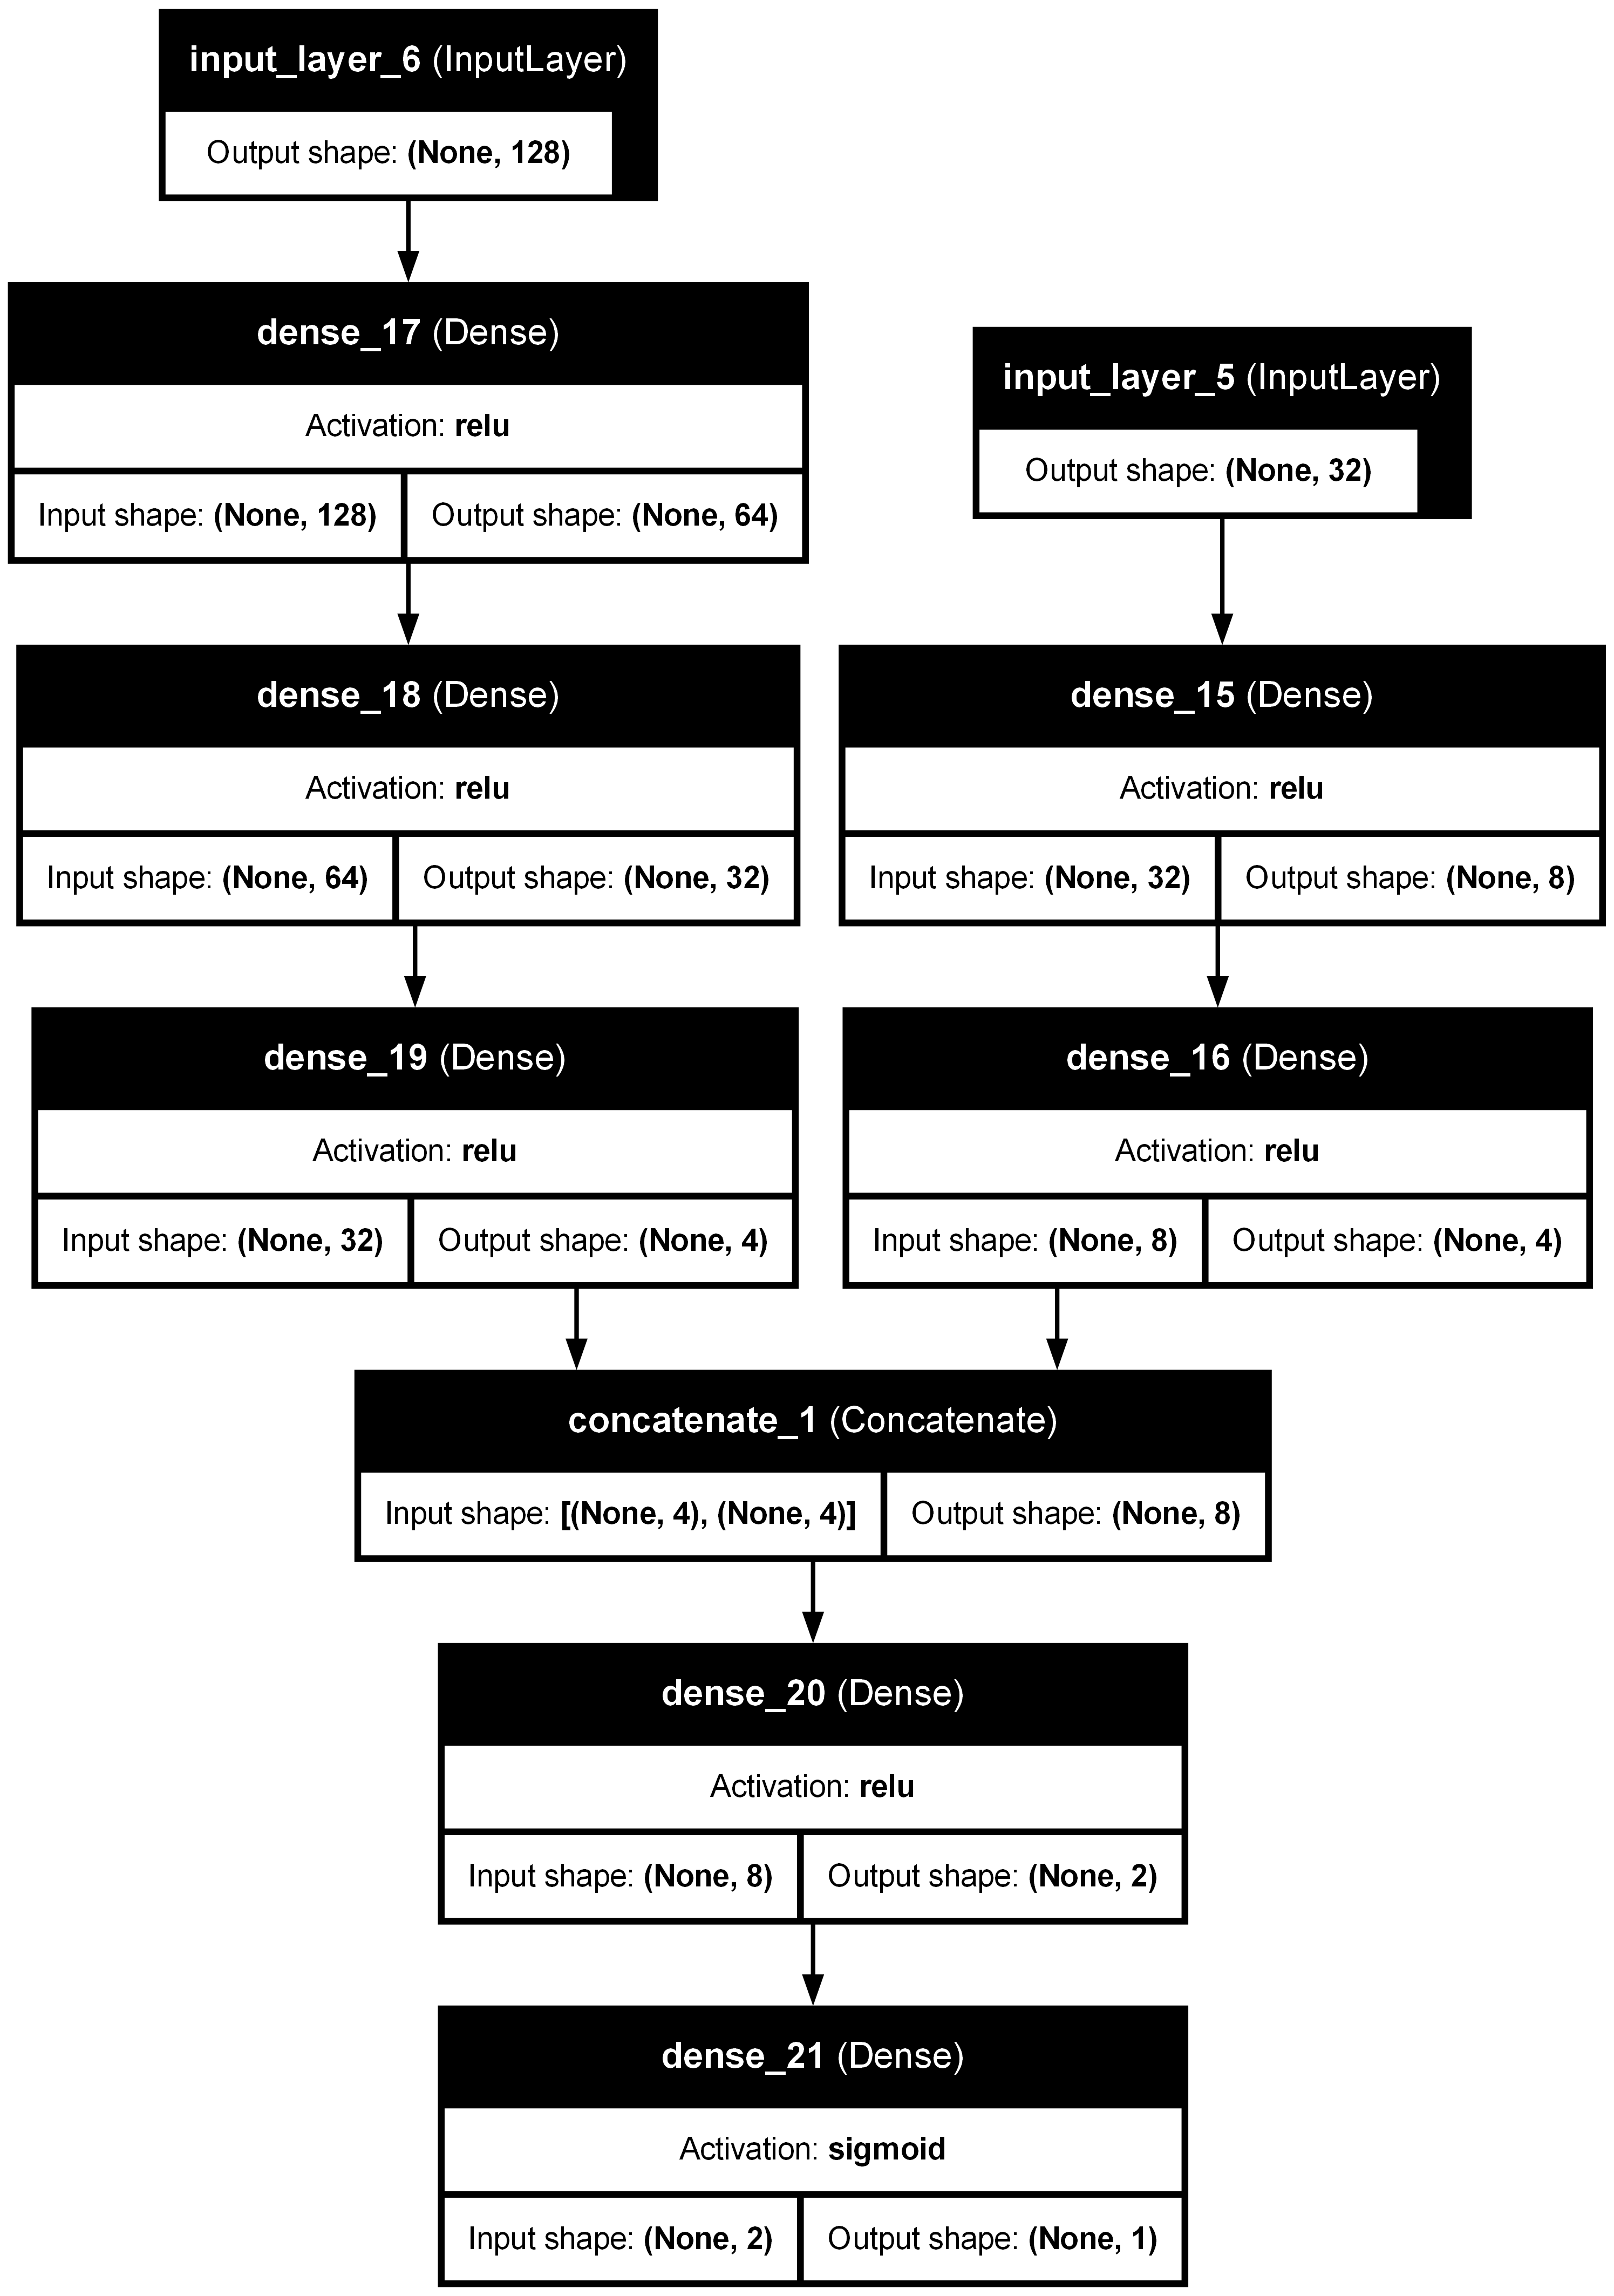

In [25]:
plot_model(model,show_shapes=True,to_file= f'{curr_dir}/Dataset/output_images/two_input_architecture.png', show_layer_names=True, show_layer_activations=True, rankdir='TB', expand_nested=True, dpi = 300)